In [1]:
import sys
from pathlib import Path

ROOT_DIR = Path.cwd().parent
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))

import matplotlib.pyplot as plt
from src.config import Config
from src.utils.seed import set_seed
from src.utils.io_helpers import save_checkpoint, save_json
from src.dataset import get_dataloaders
from src.models.sparse_ae import SparseAutoencoder
from src.trainers.train_ae import train_deterministic_ae
from src.evaluation.metrics import evaluate_ae_on_testset

set_seed(Config.SEED)
Config.ensure_dirs()
train_loader, val_loader, test_loader = get_dataloaders(batch_size=Config.BATCH_SIZE, seed=Config.SEED, num_workers=0)

sparse_ae = SparseAutoencoder(
    input_dim=Config.INPUT_DIM,
    hidden_dim=Config.SPARSE_AE_HIDDEN_DIM,
    latent_dim=Config.SPARSE_AE_LATENT_DIM,
)

train_out = train_deterministic_ae(
    model=sparse_ae,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=Config.SPARSE_AE_EPOCHS,
    lr=Config.SPARSE_AE_LR,
    device=Config.DEVICE,
    l1_lambda=Config.SPARSE_L1_LAMBDA,
    model_name="Sparse AE",
)

test_metrics, latency_ms = evaluate_ae_on_testset(sparse_ae, test_loader, Config.DEVICE, is_vae=False)
print(f"Sparse AE Test Metrics: {test_metrics} | Latency (batch=64): {latency_ms} ms")

save_checkpoint(sparse_ae, Config.CHECKPOINT_DIR / "sparse_ae.pth")
save_json(
    {
        "model": "Sparse Autoencoder",
        "latent_dim": Config.SPARSE_AE_LATENT_DIM,
        "l1_lambda": Config.SPARSE_L1_LAMBDA,
        "avg_epoch_time_sec": train_out["avg_epoch_time_sec"],
        "inference_latency_ms_batch64": latency_ms,
        "test_metrics": test_metrics,
        "history": train_out["history"],
    },
    Config.METRICS_DIR / "sparse_ae_results.json",
)

[Sparse AE] Epoch 01/30 | Train Loss: 0.034981 (MSE: 0.034814) | Val MSE: 0.019775 | Time: 7.44s
[Sparse AE] Epoch 05/30 | Train Loss: 0.012497 (MSE: 0.012320) | Val MSE: 0.012224 | Time: 7.98s
[Sparse AE] Epoch 10/30 | Train Loss: 0.010024 (MSE: 0.009856) | Val MSE: 0.010016 | Time: 9.09s
[Sparse AE] Epoch 15/30 | Train Loss: 0.009089 (MSE: 0.008929) | Val MSE: 0.009134 | Time: 13.85s
[Sparse AE] Epoch 20/30 | Train Loss: 0.008598 (MSE: 0.008443) | Val MSE: 0.008798 | Time: 14.61s
[Sparse AE] Epoch 25/30 | Train Loss: 0.008305 (MSE: 0.008155) | Val MSE: 0.008461 | Time: 13.73s
[Sparse AE] Epoch 30/30 | Train Loss: 0.008097 (MSE: 0.007953) | Val MSE: 0.008303 | Time: 14.10s
Sparse AE Test Metrics: {'mse': 0.008236, 'psnr': 20.8431, 'ssim': 0.8356, 'latent_zero_ratio': 0.3704} | Latency (batch=64): 0.5817 ms


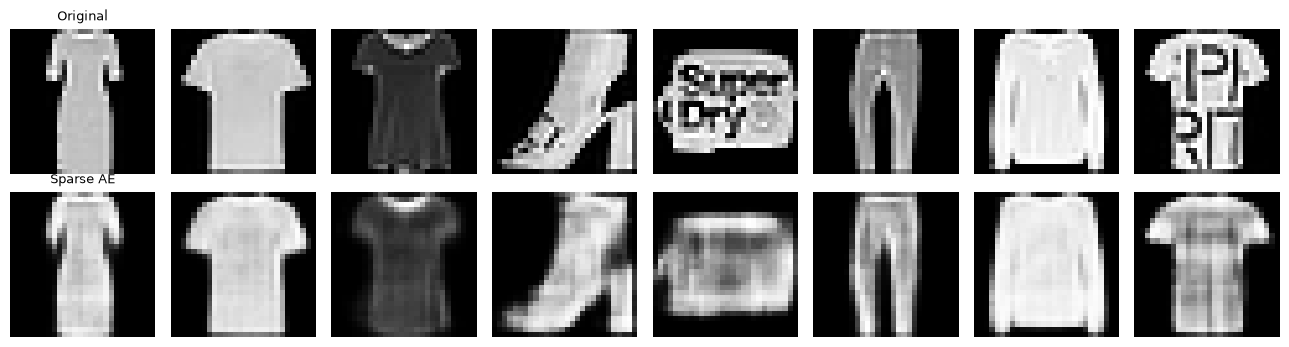

In [2]:
sample_x, _ = next(iter(test_loader))
sample_x = sample_x[:8].to(Config.DEVICE)
recon_x, _ = sparse_ae(sample_x)

fig, axes = plt.subplots(2, 8, figsize=(13, 3.5))
for i in range(8):
    axes[0, i].imshow(sample_x[i].cpu().squeeze(), cmap="gray")
    axes[0, i].axis("off")
    axes[1, i].imshow(recon_x[i].detach().cpu().squeeze(), cmap="gray")
    axes[1, i].axis("off")
axes[0, 0].set_title("Original", fontsize=9)
axes[1, 0].set_title("Sparse AE", fontsize=9)
plt.tight_layout()
plt.show()